In [1]:
import numpy as np
import matplotlib.pylab as plt
import math
import pandas as pd
import seaborn as sns
import os
from matplotlib import rcParams
import pickle
from Functions.Graphs import *
from Functions.Utils import *


# Fault-type clustering pipeline — XJTU-SY Bearing1_5

1. Load the records (32768 samples at 25.6 kHz, one per minute).
2. Characteristic fault frequencies (bearing kinematics).
3. **Stage layer**: DSI (Mahalanobis distance to the healthy baseline + EWMA) and FPT (3σ, consecutive trigger).
4. Demodulation band selection (kurtogram-like spectral kurtosis).
5. **Fault signature**: envelope-spectrum prominence at BPFO / BPFI / BSF / FTF harmonics and sidebands, in baseline-σ units.
6. **Fault layer**: clustering of the degraded records only (TEDA/AutoCloud online, GMM offline reference).

In [2]:
from scipy.stats import kurtosis
from sklearn.covariance import LedoitWolf
from sklearn.mixture import GaussianMixture

path = r"C:\Users\Usuario\Desktop\Python\Datasets\Bearings XJTU\XJTU-SY_Bearing_Datasets\Bearing2_3"
#path = r"C:\Users\Usuario\Desktop\Python\Datasets\Bearings XJTU\XJTU-SY_Bearing_Datasets\37.5Hz11kN\Bearing2_1"
fs = 25600            # XJTU-SY sampling rate [Hz]
fr = 2250 / 60        # condition 1 (Bearing1_x): 2100 rpm -> 35 Hz

# LDK UER204 geometry (Wang et al., IEEE Trans. Reliab., 2020)
n_balls, d_ball, D_pitch, alpha = 8, 7.92, 34.55, 0.0

# the .pkz files in Dataset\B1_5 were written by the cell above with df.to_csv -> read as csv
files = sorted(os.listdir(path), key=lambda x: int(x.split('.')[0]))
X = np.array([pd.read_csv(os.path.join(path, f))['hor'].values for f in files])
t = np.arange(1, len(X) + 1)          # one record per minute
print(X.shape)

(533, 32768)


## 2. Characteristic fault frequencies

| Fault | Formula |
|---|---|
| Outer race (BPFO) | (n/2)·fr·(1 − d/D·cosα) |
| Inner race (BPFI) | (n/2)·fr·(1 + d/D·cosα) |
| Ball spin (BSF) | (D/2d)·fr·(1 − (d/D·cosα)²) |
| Cage (FTF) | (1/2)·fr·(1 − d/D·cosα) |

In [3]:
def fault_orders(n, d, D, alpha=0.0):
    '''Characteristic fault frequencies as multiples (orders) of the shaft frequency.'''
    r = d / D * np.cos(np.deg2rad(alpha))
    return {'BPFO': n / 2 * (1 - r),
            'BPFI': n / 2 * (1 + r),
            'BSF': D / (2 * d) * (1 - r**2),
            'FTF': 0.5 * (1 - r)}

ORDERS = fault_orders(n_balls, d_ball, D_pitch, alpha)
pd.DataFrame({'order [x fr]': ORDERS, 'frequency [Hz]': {k: v * fr for k, v in ORDERS.items()}}).round(2)

,order [x fr],frequency [Hz]
BPFO,3.08,115.62
BPFI,4.92,184.38
BSF,2.07,77.50
FTF,0.39,14.45


## 3. Stage layer: DSI and FPT

A healthy bearing has no fault signature, so fault clustering only makes sense after degradation onset. DSI = Mahalanobis distance (Ledoit-Wolf covariance) of a feature vector [log RMS, log kurtosis, log envelope-band energies] to the healthy baseline (first `n_base` records), in baseline-σ units and EWMA-smoothed. FPT = first of 3 consecutive records with DSI > 3σ.

FPT: t = 32 min


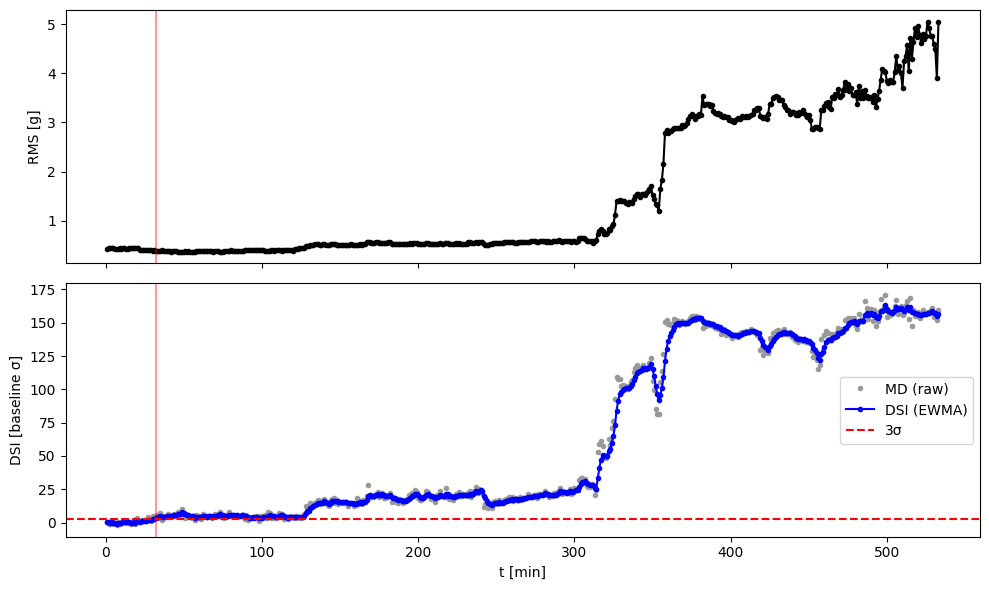

In [4]:
def envelope(x, band=None, fs=fs):
    '''Envelope via analytic signal; the band-pass is done in the frequency domain.'''
    N = len(x)
    S = np.fft.fft(x - x.mean())
    f = np.fft.fftfreq(N, 1 / fs)
    H = np.zeros(N)
    H[f > 0] = 2.0
    if band is not None:
        H[(f < band[0]) | (f > band[1])] = 0.0
    return np.abs(np.fft.ifft(S * H))

def envelope_spectrum(x, band=None, fs=fs):
    env = envelope(x, band, fs)
    env = env - env.mean()
    E = np.abs(np.fft.rfft(env * np.hanning(len(env)))) * 2 / len(env)
    return np.fft.rfftfreq(len(env), 1 / fs), E**2

def stage_features(x, n_bands=16, fmax=1000):
    '''log RMS, log kurtosis and log band energies of the envelope spectrum (0-fmax Hz).'''
    f, E = envelope_spectrum(x)
    edges = np.linspace(0, fmax, n_bands + 1)
    bands = [np.sum(E[(f >= a) & (f < b)]**2) for a, b in zip(edges[:-1], edges[1:])]
    rms = np.sqrt(np.mean(x**2))
    return np.r_[np.log10(rms), np.log10(kurtosis(x, fisher=False)), np.log10(np.array(bands) + 1e-12)]

def dsi_md(F, n_base=15, lam=0.3):
    '''Mahalanobis distance to the healthy baseline, in baseline-sigma units, EWMA-smoothed (causal).'''
    lw = LedoitWolf().fit(F[:n_base])
    md = np.sqrt(lw.mahalanobis(F))
    md = (md - md[:n_base].mean()) / md[:n_base].std()
    ewma = np.zeros_like(md)
    for i in range(len(md)):
        ewma[i] = lam * md[i] + (1 - lam) * (ewma[i - 1] if i else md[i])
    return md, ewma

def detect_fpt(dsi, thr=3.0, n_consec=3, start=0):
    '''First record of n_consec consecutive values above thr (avoids triggers by random noise).'''
    above = dsi > thr
    for k in range(start, len(dsi) - n_consec + 1):
        if above[k:k + n_consec].all():
            return k
    return None

n_base = 15
F_stage = np.array([stage_features(x) for x in X])
md, DSI = dsi_md(F_stage, n_base=n_base)
fpt = detect_fpt(DSI, start=n_base)
print('FPT: t =', t[fpt], 'min')

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(t, np.sqrt(np.mean(X**2, axis=1)), 'k.-'); ax[0].set_ylabel('RMS [g]')
ax[1].plot(t, md, '.', c='0.6', label='MD (raw)'); ax[1].plot(t, DSI, 'b.-', label='DSI (EWMA)')
ax[1].axhline(3, c='r', ls='--', label='3σ'); ax[1].set_ylabel('DSI [baseline σ]'); ax[1].set_xlabel('t [min]')
for a in ax: a.axvline(t[fpt], c='r', alpha=.4)
ax[1].legend(); fig.tight_layout(); plt.show()

## 4. Demodulation band (kurtogram-like)

Fault impacts excite a structural resonance; demodulating around it reveals the fault frequencies in the envelope spectrum. The band is chosen on a dyadic grid by maximizing the spectral kurtosis of the squared envelope over the degraded records (Antoni, 2007). Bands above 0.9·Nyquist are excluded (anti-aliasing region).

Selected band: 9600-10400 Hz


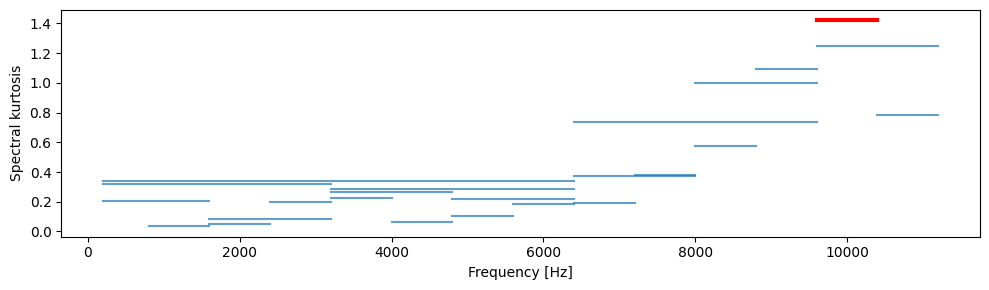

In [5]:
def band_grid(fs=fs, fr=fr, levels=(1, 2, 3, 4, 5, 6), fmin=200, fmax_ratio=0.9):
    '''Dyadic band grid (1/2^level of the Nyquist band), avoiding the anti-aliasing region.'''
    grid = []
    for lv in levels:
        bw = fs / 2 / 2**lv
        for i in range(2**lv):
            lo, hi = max(i * bw, fmin), (i + 1) * bw
            if hi - lo > 4 * max(ORDERS.values()) * fr and hi <= fmax_ratio * fs / 2:
                grid.append((lo, hi))
    return grid

def select_band(Xd, grid):
    '''Kurtogram criterion: band maximizing the spectral kurtosis (of the squared envelope) over degraded records.'''
    def sk(x, b):
        e2 = envelope(x, b)**2
        return np.mean(e2**2) / np.mean(e2)**2 - 2
    score = np.array([np.mean([sk(x, b) for x in Xd]) for b in grid])
    return grid[int(np.argmax(score))], score

grid = band_grid()
band, band_score = select_band(X[fpt:], grid)
print(f'Selected band: {band[0]:.0f}-{band[1]:.0f} Hz')

fig, ax = plt.subplots(figsize=(10, 3))
for (lo, hi), s in zip(grid, band_score):
    ax.plot([lo, hi], [s, s], c='tab:blue', alpha=.7)
ax.plot(band, [band_score.max()] * 2, c='r', lw=3)
ax.set_xlabel('Frequency [Hz]'); ax.set_ylabel('Spectral kurtosis'); fig.tight_layout(); plt.show()

## 5. Fault signature vector

For each characteristic order (BPFO, BPFI, BSF, FTF) and its harmonics 1–3×, plus the BPFI ±fr and 2·BSF ±FTF sidebands: the peak within ±3 % (slip) of the envelope spectrum relative to its local median (noise floor), in log10. Each feature is then z-scored with the healthy baseline (first `n_base` records), and the **fault index** of each type is the mean z-score of its features.

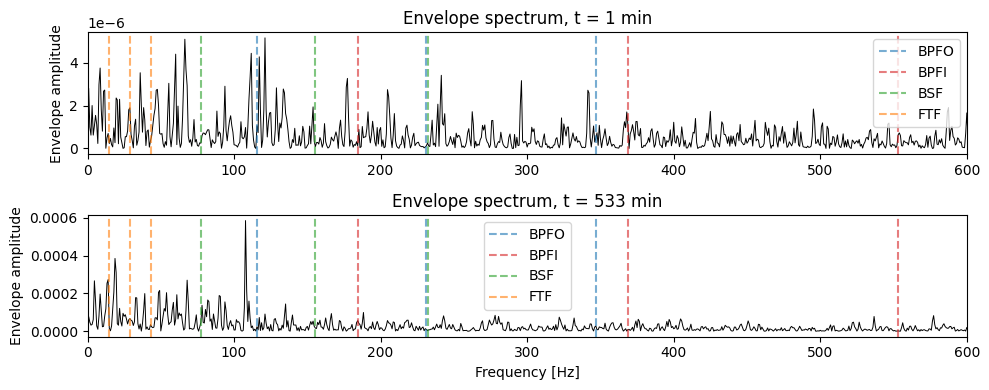

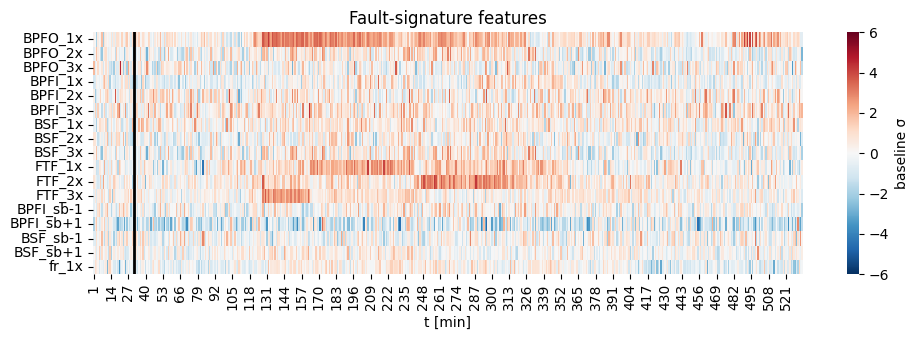

In [6]:
def peak_ratio(f, E, fc, tol=0.03, floor_win=0.2):
    '''Peak within ±tol of fc relative to the local median (noise floor) of the envelope spectrum.'''
    win = (f > fc * (1 - tol)) & (f < fc * (1 + tol))
    ref = (f > fc * (1 - floor_win)) & (f < fc * (1 + floor_win))
    return E[win].max() / (np.median(E[ref]) + 1e-12)

def fault_signature(x, band, fr=fr, n_harm=3):
    f, E = envelope_spectrum(x, band)
    feats = {}
    for name, o in ORDERS.items():
        for h in range(1, n_harm + 1):
            feats[f'{name}_{h}x'] = np.log10(peak_ratio(f, E, h * o * fr))
    for s in (-1, 1):   # inner race: shaft-rate sidebands (load-zone modulation)
        feats[f'BPFI_sb{s:+d}'] = np.log10(peak_ratio(f, E, ORDERS['BPFI'] * fr + s * fr))
    for s in (-1, 1):   # rolling element: cage-rate sidebands
        feats[f'BSF_sb{s:+d}'] = np.log10(peak_ratio(f, E, 2 * ORDERS['BSF'] * fr + s * ORDERS['FTF'] * fr))
    feats['fr_1x'] = np.log10(peak_ratio(f, E, fr))
    return feats

SIG = pd.DataFrame([fault_signature(x, band) for x in X], index=t)

# z-score relative to the healthy baseline: "how many baseline sigmas above normal"
mu0, sd0 = SIG.iloc[:n_base].mean(), SIG.iloc[:n_base].std() + 1e-6
Z = (SIG - mu0) / sd0

# fault index per type: mean z-score of its harmonics (and sidebands)
FI = pd.DataFrame({k: Z[[c for c in Z.columns if c.startswith(k)]].mean(axis=1) for k in ORDERS}, index=t)

cols = dict(BPFO='tab:blue', BPFI='tab:red', BSF='tab:green', FTF='tab:orange')
fig, ax = plt.subplots(2, 1, figsize=(10, 4))
for a, k in zip(ax, [0, len(X) - 1]):
    f, E = envelope_spectrum(X[k], band)
    a.plot(f, E, 'k', lw=.7); a.set_xlim(0, 600)
    for name, o in ORDERS.items():
        for h in range(1, 4):
            a.axvline(h * o * fr, c=cols[name], ls='--', alpha=.6, label=name if h == 1 else None)
    a.set_ylabel('Envelope amplitude'); a.set_title(f'Envelope spectrum, t = {t[k]} min'); a.legend()
ax[1].set_xlabel('Frequency [Hz]')
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(Z.T, cmap='RdBu_r', center=0, vmin=-6, vmax=6, ax=ax, cbar_kws={'label': 'baseline σ'})
ax.axvline(fpt, c='k', lw=2); ax.set_xlabel('t [min]'); ax.set_title('Fault-signature features')
fig.tight_layout(); plt.show()

c:\Users\Usuario\Desktop\Python\Batteries_Prognostics\.venv\lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in sqrt
  result = func(self.values, **kwargs)


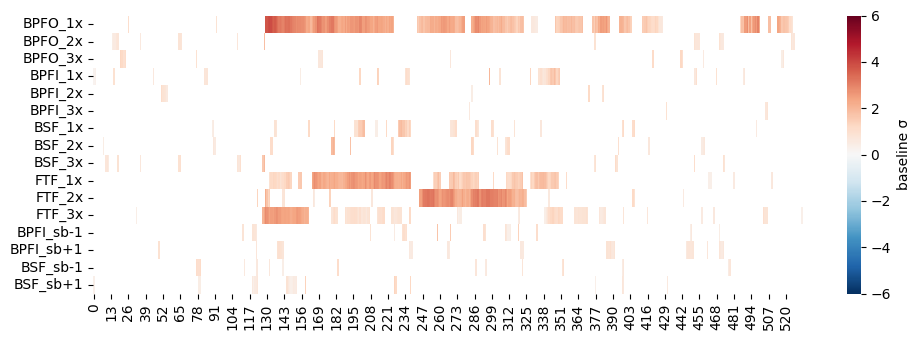

In [22]:
w = 5
path = r'Dataset\DSI\Horizontal\Bearing2_3.csv'
Z1 = pd.read_csv(path).iloc[:,1:-1]

path = r'Dataset\DSI\Vertical\Bearing2_3.csv'
Z2 = pd.read_csv(path).iloc[:,1:-1]

Z3 = np.sqrt(Z1*Z2)

Z3 = moving_average_df(Z3,w)

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(Z3.T, cmap='RdBu_r', center=0, vmin=-6, vmax=6, ax=ax, cbar_kws={'label': 'baseline σ'})
fig.tight_layout(); plt.show()


## Z for every bearing and direction

`compute_Z(bearing_path)` reads the operating condition from the folder name `BearingN_X` (1: 35 Hz / 12 kN, 2: 37.5 Hz / 11 kN, 3: 40 Hz / 10 kN). Only the shaft frequency `fr` changes; the fault orders (BPFO, BPFI, BSF, FTF ×fr) depend on the bearing geometry. For each direction (`hor`, `ver`) it runs DSI → FPT → band → fault signature → Z, and saves `Dataset\DSI\<Horizontal|Vertical>\BearingN_X.csv`. The FPT and band used for each Z are stored in `Dataset\DSI\summary.csv`.

In [8]:
import re
print(xxx)
CONDITIONS = {1: (35.0, 12), 2: (37.5, 11), 3: (40.0, 10)}   # N: (shaft frequency fr [Hz], radial load [kN])
DSIPath = r'Dataset\DSI'

def bearing_condition(bearing_path):
    '''Operating condition from the folder name BearingN_X -> (name, fr, load).'''
    name = os.path.basename(os.path.normpath(bearing_path))
    m = re.fullmatch(r'Bearing(\d)_(\d+)', name)
    if m is None or int(m.group(1)) not in CONDITIONS:
        raise ValueError(f'Folder name must be BearingN_X with N in {list(CONDITIONS)}: {name}')
    fr, load = CONDITIONS[int(m.group(1))]
    return name, fr, load

def load_bearing(bearing_path):
    '''All records (1.csv, 2.csv, ...) of a bearing -> {'Horizontal': (records, samples), 'Vertical': ...}.'''
    files = sorted((f for f in os.listdir(bearing_path) if f.endswith('.csv')), key=lambda x: int(x.split('.')[0]))
    first = pd.read_csv(os.path.join(bearing_path, files[0]), usecols=['hor', 'ver'])
    data = np.empty((len(files), len(first), 2), dtype=np.float32)
    for k, f in enumerate(files):
        data[k] = pd.read_csv(os.path.join(bearing_path, f), usecols=['hor', 'ver'])[['hor', 'ver']].values
    return {'Horizontal': data[:, :, 0], 'Vertical': data[:, :, 1]}

def compute_Z_direction(X, fr, n_base=15, max_band_records=50):
    '''Stage layer (DSI, FPT) -> demodulation band -> fault signature -> z-score w.r.t. the healthy baseline.'''
    t = np.arange(1, len(X) + 1)
    F_stage = np.array([stage_features(x) for x in X])
    _, dsi = dsi_md(F_stage, n_base=n_base)
    fpt = detect_fpt(dsi, start=n_base)
    k0 = fpt if fpt is not None else int(0.8 * len(X))       # no onset detected: last 20 % of life
    # band selection on (at most) max_band_records evenly spaced degraded records
    idx = np.unique(np.linspace(k0, len(X) - 1, min(max_band_records, len(X) - k0)).astype(int))
    band, _ = select_band(X[idx], band_grid(fr=fr))
    SIG = pd.DataFrame([fault_signature(x, band, fr=fr) for x in X], index=t)
    Z = (SIG - SIG.iloc[:n_base].mean()) / (SIG.iloc[:n_base].std() + 1e-6)
    Z.index.name = 't'
    return Z, fpt, band

def compute_Z(bearing_path, out_root=DSIPath, n_base=15):
    '''Z for the horizontal and vertical vibration of a bearing, saved at out_root\\Horizontal and out_root\\Vertical.'''
    name, fr, load = bearing_condition(bearing_path)
    freqs = {k: round(float(o * fr), 2) for k, o in ORDERS.items()}
    print(f'{name}: fr = {fr} Hz, {load} kN -> {freqs} Hz')

    results, rows = {}, []
    for direction, X in load_bearing(bearing_path).items():
        Z, fpt, band = compute_Z_direction(X, fr, n_base)
        out_dir = os.path.join(out_root, direction)
        os.makedirs(out_dir, exist_ok=True)
        Z.to_csv(os.path.join(out_dir, f'{name}.csv'))
        results[direction] = Z
        rows.append(dict(bearing=name, direction=direction, fr=fr, load_kN=load, records=len(Z),
                         FPT=fpt + 1 if fpt is not None else np.nan, band_lo=band[0], band_hi=band[1], **freqs))
        print(f'  {direction:<10}: {len(Z)} records, FPT t = {rows[-1]["FPT"]}, band {band[0]:.0f}-{band[1]:.0f} Hz')

    # summary of the parameters used for each Z (one row per bearing/direction)
    summary_file = os.path.join(out_root, f'{bearing_path}.csv')
    new = pd.DataFrame(rows)
    if os.path.exists(summary_file):
        old = pd.read_csv(summary_file)
        new = pd.concat([old[old['bearing'] != name], new]).sort_values(['bearing', 'direction'])
    new.to_csv(summary_file, index=False)
    return results

NameError: name 'xxx' is not defined

In [ ]:
XJTUPath = r"C:\Users\Usuario\Desktop\Python\Datasets\Bearings XJTU\XJTU-SY_Bearing_Datasets"

# a single bearing
#res = compute_Z(os.path.join(XJTUPath, 'Bearing1_5'))

# all bearings (Bearing3_1 / 3_2 / 3_4 have > 1500 records: slow)
for name in sorted(os.listdir(XJTUPath)):
    compute_Z(os.path.join(XJTUPath, name))

Bearing1_1: fr = 35.0 Hz, 12 kN -> {'BPFO': 107.91, 'BPFI': 172.09, 'BSF': 72.33, 'FTF': 13.49} Hz
  Horizontal: 123 records, FPT t = 17, band 9600-10400 Hz
  Vertical  : 123 records, FPT t = 17, band 9600-10400 Hz
Bearing1_2: fr = 35.0 Hz, 12 kN -> {'BPFO': 107.91, 'BPFI': 172.09, 'BSF': 72.33, 'FTF': 13.49} Hz
  Horizontal: 161 records, FPT t = 16, band 9600-11200 Hz
  Vertical  : 161 records, FPT t = 31, band 10400-11200 Hz
Bearing1_3: fr = 35.0 Hz, 12 kN -> {'BPFO': 107.91, 'BPFI': 172.09, 'BSF': 72.33, 'FTF': 13.49} Hz
  Horizontal: 158 records, FPT t = 59, band 9600-11200 Hz
  Vertical  : 158 records, FPT t = 28, band 10400-11200 Hz
Bearing1_4: fr = 35.0 Hz, 12 kN -> {'BPFO': 107.91, 'BPFI': 172.09, 'BSF': 72.33, 'FTF': 13.49} Hz
  Horizontal: 122 records, FPT t = 17, band 9600-11200 Hz
  Vertical  : 122 records, FPT t = 18, band 4800-6400 Hz
Bearing1_5: fr = 35.0 Hz, 12 kN -> {'BPFO': 107.91, 'BPFI': 172.09, 'BSF': 72.33, 'FTF': 13.49} Hz
  Horizontal: 52 records, FPT t = 26, ba